# From tells to Cyprus
**Instructor copy · a four-hour workshop, including discussion and optional experiments**

An archaeology team can inspect **50 images**. Can a model put useful ones first?
A *tell* is a mound built up by repeated human occupation. We will learn from labelled
tell images, compare two simple classifiers, and see what changes in Cyprus.

Run the notebook from top to bottom. The code is complete; your work is to inspect the
results and decide what they justify. You will hand in a ranked CSV and **one short
recommendation**. A high score is a reason to look, not proof of a site.

Use Jupyter or upload this file to [Google Colab](https://colab.research.google.com/).
You need basic Python and pandas. No GPU, API key or model download is required.
Setup installs missing packages; the first data load downloads about 73 MB of images.
Allow about 400 MB of disk space. A facilitator-provided `enki_workshop_sample.zip`
can be placed in `archaeology_workshop/` to avoid that download.

This copy follows the same code path as the participant notebook. It adds discussion
notes at the end, a sample recommendation, and an enabled final test reveal.
Keep it for the debrief. The holdout is educational: source labels are public.

## 1. Look at the images

Run the folded setup cell once. It unpacks the data and small helpers for downloading,
checking and plotting. Their source is in `archaeology_workshop/assets/workshop_helpers.py`.
The modelling code appears below.

In [1]:
# @title Setup — run once; no edits needed
import base64, importlib.util, io, os, shutil, subprocess, sys, zipfile
from pathlib import Path

requirements = {"numpy": "numpy>=1.24,<3", "pandas": "pandas>=2.1,<4",
                "matplotlib": "matplotlib>=3.8,<4", "sklearn": "scikit-learn>=1.4,<2",
                "PIL": "pillow>=10,<14", "imagehash": "ImageHash==4.3.2",
                "requests": "requests>=2.31,<3", "tqdm": "tqdm>=4.66,<5"}
missing = [package for module, package in requirements.items()
           if importlib.util.find_spec(module) is None]
if missing and not os.environ.get("ARCHAEOLOGY_SKIP_INSTALL"):
    installer = ([sys.executable, "-m", "pip", "install", "-q"]
                 if importlib.util.find_spec("pip") else
                 [shutil.which("uv") or "uv", "pip", "install", "--python", sys.executable, "-q"])
    subprocess.check_call(installer + missing)

ROOT = Path(os.environ.get("ARCHAEOLOGY_WORKSHOP_ROOT", "archaeology_workshop"))
assets = ROOT / "assets"
assets.mkdir(parents=True, exist_ok=True)
ASSET_B64 = "..."
with zipfile.ZipFile(io.BytesIO(base64.b64decode(ASSET_B64))) as bundle:
    for name in bundle.namelist():
        if not (assets / name).resolve().is_relative_to(assets.resolve()):
            raise ValueError("Unsafe asset path")
    bundle.extractall(assets)
del ASSET_B64
spec = importlib.util.spec_from_file_location("workshop_helpers", assets / "workshop_helpers.py")
workshop = importlib.util.module_from_spec(spec)
spec.loader.exec_module(workshop)
print("Ready. Run the next cell to load the images.")


Ready. Run the next cell to load the images.


The Enki sample starts with 300 source-labelled tell images (`1`) and 300 negatives (`0`).
This balance is for teaching; it does not estimate how common tells are in the landscape.
We remove similar images before splitting, then use at most 100 training examples per class.
The rest of the training pool is unused to keep that label budget.

**Train** fits the model. **Validation** chooses between models. **Test** stays untouched
until the final reveal. Similarity filtering reduces duplication but cannot establish
independent sites or regions: the source lacks verified geographic groups.

Index and audit images:   0%|          | 0/600 [00:00<?, ?it/s]

600 images → 593 after filtering.


,tiles
train,200
validation,119
test,119


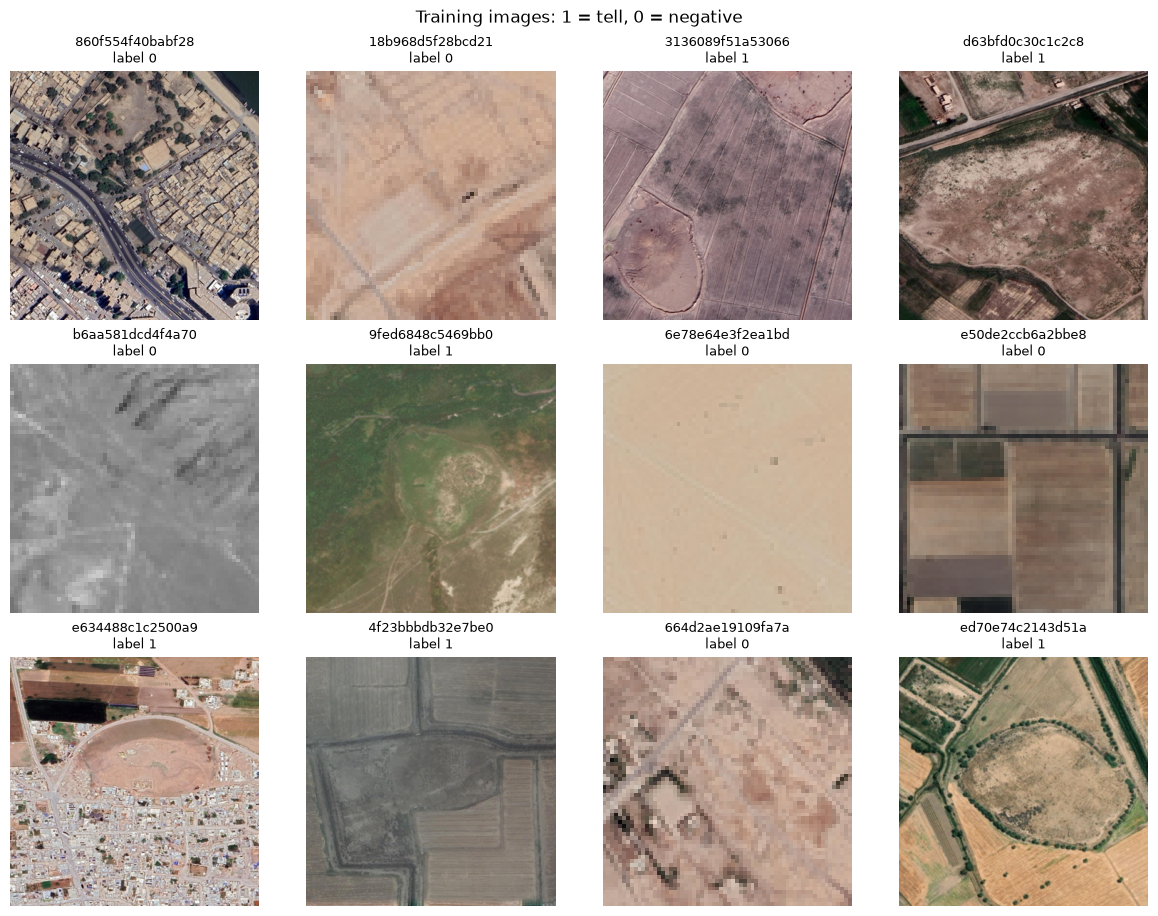

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, FileLink
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

archive = workshop.download_enki_sample(assets / "sample_manifest.json", ROOT / "enki_workshop_sample.zip")
images = workshop.index_enki(archive, ROOT / "images")
images, duplicate_audit, audit = workshop.deduplicate_images(images)
splits = workshop.workshop_split(images, per_class=100)
train, validation, test = (splits[name] for name in ("train", "validation", "test"))
print(f"{audit['raw_images']} images → {len(images)} after filtering.")
display(pd.Series({name: len(part) for name, part in splits.items()}, name="tiles").to_frame())
workshop.contact_sheet(train.sample(12, random_state=42), title="Training images: 1 = tell, 0 = negative")


**Discuss:** which differences might be archaeological, and which could be shortcuts
such as sharpness, colour or land cover? Pick one image to support your answer.

## 2. What makes a useful shortlist?

We rank images by score and review the first **50**. A *hit* is a source-labelled positive
in that shortlist. **Precision = hits / images reviewed. Recall = hits / all positives.**
We choose the model with higher validation recall at this budget. Average precision
(**AP**) summarises the full ranking and breaks a tie.

**Predict, then run:** the labels below are already in ranked order. If you review two
images, what are precision and recall? Change `k` to 4 and explain the difference.

In [3]:
ranked_labels = np.array([1, 0, 1, 1, 0])  # An invented example, not test data.
k = 2
hits = ranked_labels[:k].sum()
print(f"Hits: {hits}")
print(f"Precision: {hits / len(ranked_labels[:k]):.2f}")
print(f"Recall: {hits / ranked_labels.sum():.2f}")


Hits: 1
Precision: 0.50
Recall: 0.33


## 3. Compare two models

Both models use the same training images and logistic regression. Only their image
descriptions differ:

- **Colour/texture:** simple colour and edge measurements.
- **DINOv2:** 384 features from a pretrained image encoder. We load the supplied features;
  the encoder stays frozen.

The pipeline learns scaling from training data only. We fix regularisation at `C=1`
to keep this a two-model comparison. Scores set an ordering; they are not verified
probabilities of archaeology.

In [4]:
feature_sets = {
    "colour_texture": workshop.partition_features(
        images, workshop.handcrafted_features(images.path), splits),
    "dinov2": workshop.partition_features(
        images, workshop.load_embedding_cache(images, assets / "enki_embeddings.npz"), splits),
}
print("Training feature shapes:", {name: features["train"].shape for name, features in feature_sets.items()})


Colour and texture features:   0%|          | 0/593 [00:00<?, ?it/s]

Training feature shapes: {'colour_texture': (200, 68), 'dinov2': (200, 384)}


In [5]:
REVIEW_BUDGET = 50
models, validation_scores, rows = {}, {}, []
for name, features in feature_sets.items():
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(C=1, class_weight="balanced", max_iter=2000, random_state=42),
    )
    models[name] = model.fit(features["train"], train.label)
    validation_scores[name] = model.predict_proba(features["validation"])[:, 1]
    rows.append({"model": name, **workshop.ranking_metrics(
        validation.label, validation_scores[name], k=REVIEW_BUDGET)})

results = pd.DataFrame(rows).sort_values(
    ["recall_at_k", "AP", "model"], ascending=[False, False, True],
).reset_index(drop=True)
selected = results.iloc[0]["model"]
display(results.round(3))
print("Selected using validation:", selected)
print(f"Expected random recall: {min(REVIEW_BUDGET, len(validation)) / len(validation):.3f}")
positives = int(validation.label.sum())
print(f"Recall ceiling ({positives} positives): {min(REVIEW_BUDGET, positives) / positives:.3f}")


,model,hits,reviewed,precision_at_k,recall_at_k,AP
0,dinov2,50,50,1.0,0.833,0.996
1,colour_texture,40,50,0.8,0.667,0.864


Selected using validation: dinov2
Expected random recall: 0.420
Recall ceiling (60 positives): 0.833


**Decide:** how many more positives does the winning model find within 50 reviews?
Is that enough evidence to use it in a new region? Keep this choice for the remaining cells.

## 4. Inspect the shortlist

The first row shows source negatives **inside** the 50-image shortlist. The second shows
source positives **outside** it. These are mistakes at our review budget, not at an arbitrary
score threshold. A positive can be missed simply because the review budget is too small.
Either row can be empty.

dinov2: source negatives in the shortlist: none.


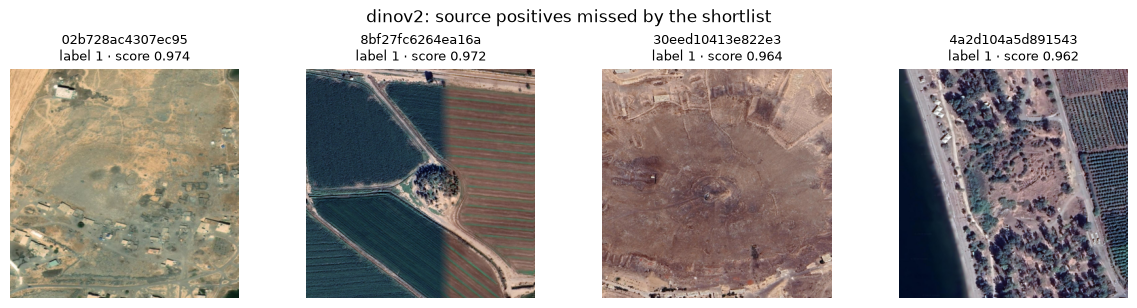

In [6]:
review = validation.assign(score=validation_scores[selected]).sort_values(
    "score", ascending=False, kind="stable")
false_alarms = review.head(REVIEW_BUDGET).query("label == 0")
misses = review.iloc[REVIEW_BUDGET:].query("label == 1")
workshop.contact_sheet(false_alarms, false_alarms.score.to_numpy(), n=4,
                       title=f"{selected}: source negatives in the shortlist")
workshop.contact_sheet(misses, misses.score.to_numpy(), n=4,
                       title=f"{selected}: source positives missed by the shortlist")


**Inspect one mistake:** note its tile ID and a visible feature that might explain the score.
Separate what you can see from your hypothesis about the model. What evidence would test it?
Use this observation in your final recommendation.

## 5. Try the same model in Cyprus

These 12 Sentinel-2 images are 1 km squares at 10 m per pixel, from 5 August 2024.
Six are centred on catalogued settlements; six are nearby **unlabelled locations**.
We apply the selected Enki model unchanged.

A catalogue entry records occupation, not whether remains are visible today. One settlement
can have several occupation rows. A nearby unlabelled location is not a confirmed absence.
**There is no detection-accuracy score for this sample.**

Colour and texture features:   0%|          | 0/12 [00:00<?, ?it/s]

,tile_id,kind,score
6,CY5_background,unlabelled_background,0.233
3,CY479_site,catalogued_location,0.215
10,CY754_background,unlabelled_background,0.092
1,CY1451_site,catalogued_location,0.092
4,CY523_background,unlabelled_background,0.060
5,CY523_site,catalogued_location,0.043
8,CY71_background,unlabelled_background,0.039
2,CY479_background,unlabelled_background,0.015
11,CY754_site,catalogued_location,0.009
0,CY1451_background,unlabelled_background,0.005


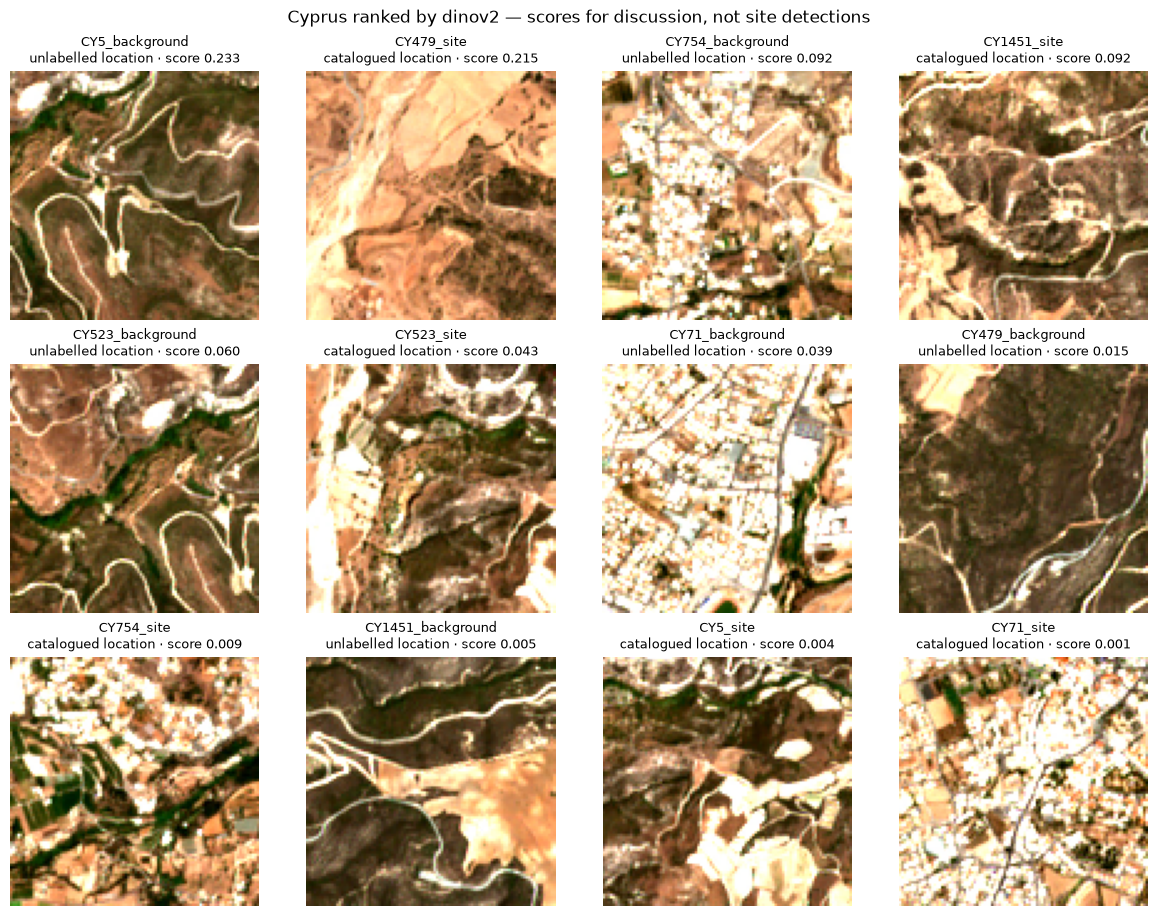

In [7]:
cyprus, cyprus_dino = workshop.load_cyprus(assets)
cyprus_features = {
    "colour_texture": workshop.handcrafted_features(cyprus.path),
    "dinov2": cyprus_dino,
}
cyprus["score"] = models[selected].predict_proba(cyprus_features[selected])[:, 1]
cyprus = cyprus.sort_values("score", ascending=False, kind="stable")
display(cyprus[["tile_id", "kind", "score"]].round(3))
workshop.contact_sheet(cyprus, cyprus.score.to_numpy(), n=12, show_labels=False,
                       title=f"Cyprus ranked by {selected} — scores for discussion, not site detections")


**Compare:** find a high-scoring unlabelled location and a low-scoring catalogued one.
How do resolution, landscape and the meaning of the labels differ from Enki?
What would you need before calling either prediction wrong?

## 6. Make a recommendation and export

Write **4–6 sentences** between the triple quotes below. Include your chosen model and
validation result, one image observation, why Cyprus does not establish accuracy, and the
evidence you would collect next. Recommending against deployment is a valid conclusion.

The export cell freezes the current choice and scores the test images without revealing
their labels. It saves `team_submission.zip` with the ranked CSV, configuration, validation
results, Cyprus scores and your recommendation. Download the ZIP and save this notebook.

In [8]:
winner = results.iloc[0]
recommendation = (
    f"Use {selected} only to prioritise expert review of imagery similar to this sample. "
    f"On validation it finds {int(winner.hits)} positives in {int(winner.reviewed)} reviews "
    f"(recall {winner.recall_at_k:.3f}, precision {winner.precision_at_k:.3f}). "
    "Validation tile 8bf27fc6264ea16a shows a small tree-covered patch between fields; "
    "this is an observation to discuss with an expert, not proof of what the model uses. "
    "Cyprus accuracy is unknown because catalogue membership is not an image-visibility "
    "label and the other locations are unlabelled. "
    "Before field deployment, obtain expert visibility labels and an independent "
    "geographic holdout using imagery appropriate to the size of the features sought."
)


In [9]:
test_scores = models[selected].predict_proba(feature_sets[selected]["test"])[:, 1]
submission = workshop.write_submission(test, test_scores, ROOT / "submission.csv")
bundle = workshop.export_results(ROOT, results, cyprus, recommendation, configuration={
    "selected_model": selected, "review_budget": REVIEW_BUDGET,
    "C": models[selected].named_steps["logisticregression"].C,
    "class_weight": "balanced", "scaler": "StandardScaler",
    "training_tiles": len(train), "test_tiles": len(test),
    "sample_manifest_sha256": workshop.file_digest(assets / "sample_manifest.json"),
})
display(submission.head())
display(FileLink(str(bundle)))
print("Saved:", bundle, "— in Colab, download it from the Files panel.")


,tile_id,score,rank
0,eea5a713c2c66b35,0.999995,1
1,f76b1ac041854f4f,0.999993,2
2,4eb0092ef08a3c43,0.999960,3
3,f3b8b57a94f47a18,0.999951,4
4,fe336ee05755bbef,0.999941,5


/Users/orbitfold/Programming/archaeology-challenge/archaeology-challenge/.work/instructor_execution/archaeology_workshop/team_submission.zip

Saved: archaeology_workshop/team_submission.zip — in Colab, download it from the Files panel.


### Final reveal — after sharing your recommendation

Change `REVEAL_TEST` to `True` when the facilitator opens the debrief. This is the final
assessment of the saved choice; do not use it to pick another model. Recall counts positive
tiles, not independently verified sites, and this split is not a geographic holdout.

In [10]:
REVEAL_TEST = True
if REVEAL_TEST:
    final_result = workshop.score_submission(submission, test, workshop.ranking_metrics, REVIEW_BUDGET)
    display(pd.Series(final_result, name="final_test").round(3).to_frame())
    print(f"Random ordering: expected recall {min(REVIEW_BUDGET, len(test)) / len(test):.3f}.")
else:
    print("Test labels remain unused. Finish your recommendation before the reveal.")


,final_test
hits,49.000
reviewed,50.000
precision_at_k,0.980
recall_at_k,0.817
AP,0.962


Random ordering: expected recall 0.420.


### Discussion notes

- **Shortlist example:** at `k=2`, precision is 1/2 and recall is 1/3. At `k=4`,
  they are 3/4 and 3/3. The denominators answer different questions.
- **Model choice:** recall at 50 reviews comes first; AP breaks ties. A strong baseline
  can reflect useful information or shortcuts. Performance alone cannot tell us which.
- **Mistakes:** ask for a tile ID and an observation before accepting an explanation.
  The sample recommendation cites an image in the supplied validation view.
  Neither sharpness nor land cover proves what the model uses. At 50 reviews for 60
  positives, 0.833 is the maximum recall even for a perfect ranking.
- **Cyprus:** neither a low-scoring catalogue point nor a high-scoring unlabelled point
  can be called a detection error without image-visibility labels.
- **Debrief:** compare recommendations and proposed evidence, then reveal the test once.
  Discuss why a random split of similar source imagery cannot establish regional transfer.

Keep the main task to these decisions. If time permits, use the optional experiments
below. Model extraction and live imagery acquisition belong in preparation, outside class.

### Optional experiments — after the main task

Use **validation only** for experiments; leave the final test alone.

- Change `C=1` in the comparison cell to `0.1` or `10`, rerun sections 3–6, and explain
  whether the validation shortlist changed. Do this before the test reveal.
- To explore label efficiency, the helper `workshop.learning_curve_rows` repeats fits
  with 10, 25, 50 and 100 training examples per class. The recipe is in `FACILITATOR_GUIDE.md`.
- To audit the catalogue, load `assets / "Cyprus_Settlements.csv"` with pandas and run
  `workshop.summarise_sites(phases)`. It retains one record per ID and flags conflicts.
  `Long_Cord`/`Lat_Cord` are degrees; `Longitude`/`Latitude` are UTM metres.
  Quality codes A–E describe source provenance, not error radii. Blank/F codes are
  undocumented; `CY453` has conflicting coordinates and keeps no summary point.

### Data and credits

- **Enki:** [Rosati (2025)](https://zenodo.org/records/14950565), a curated 600-image sample
  from `Normalized_Tell_combined_350.zip` (whole-archive MD5 `1d4ea398ea5669f9bca4539416847206`).
  Member CRCs and decoded-pixel hashes verify the partial download. Five RGB positive
  categories are used; masked and black-and-white folders are excluded.
  The source declares CC BY-SA 4.0 and separate Google/Bing imagery conditions; retain its notices.
- **Cyprus catalogue:** [Crawford & Vella (2022)](https://doi.org/10.5334/joad.96), CC BY 4.0;
  [source revision](https://github.com/K-A-Crawford/Cyprus_Settlements/tree/70a5c3d399a2451e1d8dd5eb947eb80055276b44).
  There are 8,766 occupation rows and 1,559 settlement IDs.
- **Image features:** [DINOv2](https://github.com/facebookresearch/dinov2),
  `facebook/dinov2-small`, revision `ed25f3a31f01632728cabb09d1542f84ab7b0056`.
  Enki and Cyprus use the same full-frame preprocessing, recorded in each feature cache.
- **Cyprus imagery:** modified Copernicus Sentinel data (2024), via
  [Microsoft Planetary Computer](https://planetarycomputer.microsoft.com/dataset/sentinel-2-l2a).
  Scene `S2A_MSIL2A_20240805T082601_R021_T36SVD_20240805T144559`.
  Nearby centres are 2 km east and at least 750 m from catalogue points; chips have at least
  90% clear-land pixels. Acquisition details are in `assets/cyprus/provenance.json`.

**If a download fails:** use the facilitator's sample ZIP at the path given at the start;
do not rename the full source archive to that filename. After restarting the kernel, rerun
from the top. In Colab, download your outputs before the runtime ends.